# FIK FAIR 2026 

**Task:** prediksi *Anonymous Competition Score* dari 24 fitur numerik. **Metric:** RMSE (tie-breaker MAE).

## Alur
| Tahap | Apa yang dilakukan | Split CV |
|---|---|---|
| 1. Seleksi | Tiap keluarga model (TabICL, GP, KRR, SVR) dievaluasi dengan konfigurasi default, ambil `TOP_K` terbaik | split **TUNE** (seed 2026, `N_REP_TUNE` repeat) |
| 2. Tuning | Grid kecil per keluarga terpilih. Konfigurasi default hanya diganti bila selisih RMSE ≥ `TUNE_MARGIN` | split **TUNE** |
| 3. OOF untuk stacking | Anggota hasil tuning (dan versi default sebagai pembanding) dijalankan ulang di split **STACK** yang benar-benar baru (seed 777, `N_REP_STACK` repeat) | split **STACK** |
| 4. Stacking | Bobot non-negatif, jumlah = 1, dipelajari dari seluruh repeat sekaligus. Dievaluasi dengan CV tingkat-2 (10-fold atas baris) | — |

## Aturan keputusan final (ditulis di awal, tidak disetel dari hasil)
1. Stack dipakai hanya bila lebih baik dari rata-rata sama rata anggota tuning minimal `STACK_MARGIN` **dan** dari rata-rata anggota default minimal `TUNE_MARGIN`.
2. Bila tidak, rata-rata sama rata anggota tuning dipakai hanya bila lebih baik dari anggota default minimal `TUNE_MARGIN` **di split STACK yang baru**.
3. Bila tidak, jatuh ke rata-rata anggota default.

In [34]:
import numpy as np, pandas as pd, os, time, json, itertools, warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from joblib import Parallel, delayed
from scipy import stats
from scipy.optimize import minimize

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.kernel_ridge import KernelRidge
from sklearn.svm import SVR
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel
from sklearn.model_selection import KFold, RepeatedKFold, cross_val_predict, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error

pd.set_option('display.max_columns', None); pd.set_option('display.width', 170)
def rmse(a, b): return float(np.sqrt(mean_squared_error(a, b)))
SEED = 42; np.random.seed(SEED)

# ---- konfigurasi ----
USE_TABICL   = True
N_JOBS       = -1
N_REP_TUNE   = 2 # repeat 5-fold untuk seleksi & tuning
N_REP_STACK  = 3 # repeat 5-fold (split baru) untuk OOF stacking
SEED_TUNE, SEED_STACK = 2026, 777
TOP_K        = 3 # jumlah model terbaik yang dipertahankan
TUNE_MARGIN  = 0.03 # RMSE harus membaik >= ini agar default diganti hasil tuning
STACK_MARGIN = 0.03 # idem untuk stack vs rata-rata sama rata
SEL_TOL      = 0.03 # anggota TabICL kedua harus dalam 3% dari anggota pertama

plt.rcParams.update({'font.family':'DejaVu Serif','font.size':9})
fmt = FuncFormatter(lambda v, p: f'{v:g}'.replace('.', ','))

## 1. Load data
Data train diacak; Data test tetap berurutan agar submission sesuai dengan `record_id`.

In [21]:
DATA_DIR = '/kaggle/input/competitions/data-science-competition-fikfair2026'
if not os.path.exists(os.path.join(DATA_DIR, 'train.csv')):
    for base_dir in ('/kaggle/input', '.', 'data'):
        for root, _, files in os.walk(base_dir):
            if 'train.csv' in files and 'test.csv' in files:
                DATA_DIR = root; break
        if os.path.exists(os.path.join(DATA_DIR, 'train.csv')): break

train = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
test  = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))
FEATURES = [c for c in train.columns if c.startswith('feature_')]
train = train.sample(frac=1, random_state=SEED).reset_index(drop=True)
X, y, Xte = train[FEATURES], train['target'], test[FEATURES]

## 2. Exploratory Data Analysis

### 1. Gambar umum data (table 1)

In [22]:
print('train:', train.shape, '| test:', test.shape, '| fitur:', len(FEATURES))
print('NaN train/test :', int(train.isna().sum().sum()), int(test.isna().sum().sum()))
print('duplikat       :', int(train.duplicated().sum()), int(test.duplicated().sum()))
print('irisan record_id train-test:', len(set(train.record_id) & set(test.record_id)))
print('rata-rata fitur  : %.2f s/d %.2f' % (X.mean().min(), X.mean().max()))
print('std fitur        : %.2f s/d %.2f' % (X.std().min(), X.std().max()))
print(y.describe().round(2).to_string())
print('std (n-1)=%.2f | std (n)=%.2f' % (y.std(ddof=1), y.std(ddof=0)))

train: (382, 26) | test: (96, 25) | fitur: 24
NaN train/test : 0 0
duplikat       : 0 0
irisan record_id train-test: 0
rata-rata fitur  : -0.06 s/d 0.05
std fitur        : 0.97 s/d 1.02
count    382.00
mean      51.20
std       12.91
min       32.59
25%       39.69
50%       50.26
75%       60.17
max      100.44
std (n-1)=12.91 | std (n)=12.89


### 2. Distribusi target (Gambar 1)

skewness 0.748 | kurtosis berlebih 0.511
Shapiro-Wilk W=0.940, p=2.34e-11
skewness log(y): 0.210
pencilan IQR atas/bawah: 3 0 | baris dengan y > 80: 11


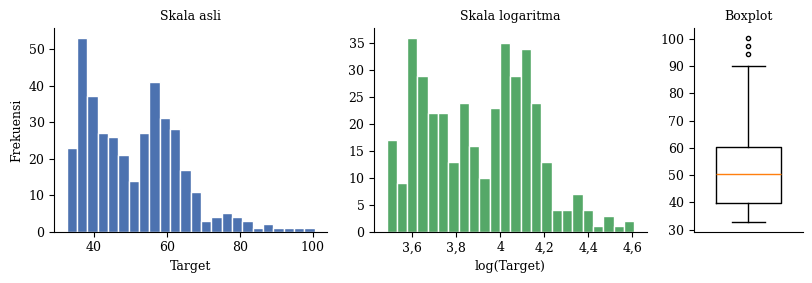

In [23]:
print('skewness %.3f | kurtosis berlebih %.3f' % (stats.skew(y), stats.kurtosis(y)))
W, p = stats.shapiro(y); print('Shapiro-Wilk W=%.3f, p=%.2e' % (W, p))
print('skewness log(y): %.3f' % stats.skew(np.log(y)))
q1, q3 = y.quantile([.25, .75]); iqr = q3 - q1
print('pencilan IQR atas/bawah:', int((y > q3 + 1.5*iqr).sum()), int((y < q1 - 1.5*iqr).sum()), '| baris dengan y > 80:', int((y > 80).sum()))

fig, ax = plt.subplots(1, 3, figsize=(8.2, 2.9), gridspec_kw={'width_ratios': [1.5, 1.5, 0.6]})
ax[0].hist(y, bins=24, color='#4C72B0', edgecolor='white'); ax[0].set_xlabel('Target'); ax[0].set_ylabel('Frekuensi'); ax[0].set_title('Skala asli', fontsize=9)
ax[1].hist(np.log(y), bins=24, color='#55A868', edgecolor='white'); ax[1].set_xlabel('log(Target)'); ax[1].set_title('Skala logaritma', fontsize=9)
ax[2].boxplot(y, widths=0.6, flierprops=dict(marker='o', ms=3)); ax[2].set_xticks([]); ax[2].set_title('Boxplot', fontsize=9)
for a in ax: a.spines[['top','right']].set_visible(False); a.xaxis.set_major_formatter(fmt)
plt.tight_layout()
plt.show()

### 3. Hubungan fitur dengan target (Gambar 2)

            pearson  spearman  p_pearson     MI
feature_09    0.391     0.420      0.000  0.190
feature_15   -0.376    -0.389      0.000  0.199
feature_12   -0.372    -0.382      0.000  0.206
feature_17    0.352     0.390      0.000  0.244
feature_13    0.348     0.389      0.000  0.261
feature_07   -0.332    -0.343      0.000  0.219
feature_03   -0.259    -0.268      0.000  0.150
feature_23    0.248     0.298      0.000  0.214
feature_20   -0.242    -0.237      0.000  0.218
feature_24    0.226     0.290      0.000  0.292
feature_14    0.214     0.183      0.000  0.168
feature_10   -0.208    -0.251      0.000  0.256
feature_04    0.205     0.255      0.000  0.146
feature_19    0.188     0.213      0.000  0.116
feature_05   -0.179    -0.179      0.000  0.092
feature_21    0.121     0.117      0.018  0.087
feature_11    0.076     0.113      0.137  0.096
feature_18   -0.059    -0.023      0.250  0.030
feature_02   -0.054    -0.108      0.292  0.064
feature_16    0.048     0.093      0.353

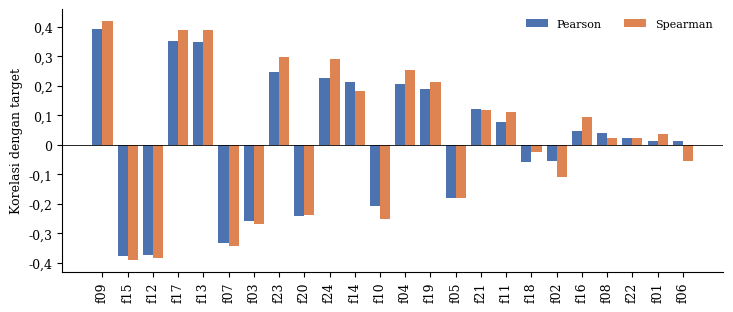

In [27]:
pe = X.apply(lambda c: stats.pearsonr(c, y)[0]);  pp = X.apply(lambda c: stats.pearsonr(c, y)[1])
sp = X.apply(lambda c: stats.spearmanr(c, y)[0])
mi = pd.Series(mutual_info_regression(X, y, random_state=0), index=FEATURES)
tab = pd.DataFrame({'pearson': pe, 'spearman': sp, 'p_pearson': pp, 'MI': mi})
tab = tab.reindex(tab.pearson.abs().sort_values(ascending=False).index)
print(tab.round(3).to_string())
print('\nsignifikan p<0,05:', int((pp < .05).sum()), '| lolos Bonferroni:', int((pp < .05/len(FEATURES)).sum()), '| max |r|: %.3f' % pe.abs().max())

o = tab.index; x = np.arange(len(o)); w = 0.4
fig, ax = plt.subplots(figsize=(7.4, 3.2))
ax.bar(x - w/2, tab.pearson, w, color='#4C72B0', label='Pearson'); ax.bar(x + w/2, tab.spearman, w, color='#DD8452', label='Spearman')
ax.axhline(0, color='k', lw=.6); ax.set_xticks(x); ax.set_xticklabels([c.replace('feature_', 'f') for c in o], rotation=90)
ax.set_ylabel('Korelasi dengan target'); ax.yaxis.set_major_formatter(fmt); ax.legend(frameon=False, ncol=2, fontsize=8); ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

### 4. Korelasi antar-fitur dan spektrum eigen (Gambar 3)

pasangan: 276 | mean |r|: 0.41 | max |r|: 0.93 | |r|>0,3: 172 | |r|>0,5: 100
varians kumulatif 1-5 komponen: [40.6 65.7 80.3 91.4 94. ] | eigen max/min: 9.74 / 0.0029 | kondisi: 3306


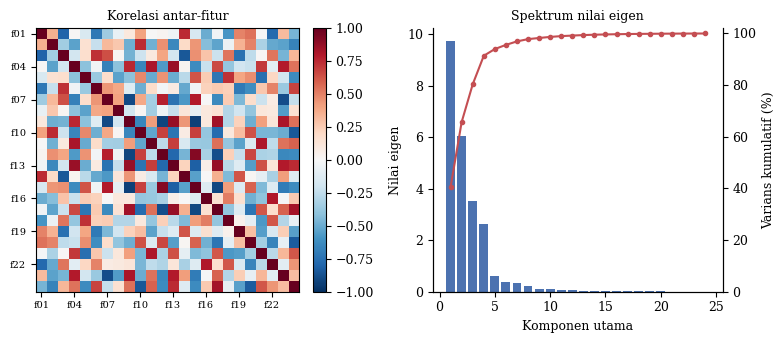

In [28]:
C = X.corr().values; off = C[np.triu_indices(len(FEATURES), 1)]
print('pasangan:', len(off), '| mean |r|: %.2f | max |r|: %.2f | |r|>0,3: %d | |r|>0,5: %d' % (np.abs(off).mean(), np.abs(off).max(), (np.abs(off) > .3).sum(), (np.abs(off) > .5).sum()))
ev = np.linalg.eigvalsh(C)[::-1]; cum = np.cumsum(ev) / ev.sum()
print('varians kumulatif 1-5 komponen:', (cum[:5] * 100).round(1), '| eigen max/min: %.2f / %.4f | kondisi: %.0f' % (ev[0], ev[-1], ev[0] / ev[-1]))

fig, ax = plt.subplots(1, 2, figsize=(8.2, 3.5), gridspec_kw={'width_ratios': [1.15, 1]})
im = ax[0].imshow(C, cmap='RdBu_r', vmin=-1, vmax=1)
ticks = range(0, len(FEATURES), 3); lab = [f'f{i+1:02d}' for i in ticks]
ax[0].set_xticks(ticks); ax[0].set_xticklabels(lab, fontsize=7); ax[0].set_yticks(ticks); ax[0].set_yticklabels(lab, fontsize=7)
plt.colorbar(im, ax=ax[0], fraction=.046, pad=.04); ax[0].set_title('Korelasi antar-fitur', fontsize=9)
ax[1].bar(range(1, len(ev)+1), ev, color='#4C72B0'); ax[1].set_xlabel('Komponen utama'); ax[1].set_ylabel('Nilai eigen'); ax[1].set_title('Spektrum nilai eigen', fontsize=9)
a2 = ax[1].twinx(); a2.plot(range(1, len(ev)+1), cum * 100, color='#C44E52', marker='o', ms=3); a2.set_ylabel('Varians kumulatif (%)'); a2.set_ylim(0, 102)
ax[1].spines[['top']].set_visible(False); a2.spines[['top']].set_visible(False)
plt.tight_layout()
plt.show()

### 5. Pencilan fitur dan kesamaan distribusi train vs test (Subbab 2.1.5)

In [35]:
z = ((X - X.mean()) / X.std()).abs()
print('sel |z|>3: %d | baris terdampak: %d (%.1f%%) | |z| maks: %.2f' % ((z > 3).sum().sum(), (z > 3).any(axis=1).sum(), 100 * (z > 3).any(axis=1).mean(), z.max().max()))

ks = pd.Series({c: stats.ks_2samp(X[c], Xte[c]).pvalue for c in FEATURES})
print('KS: fitur p<0,05 = %d dari %d | p terkecil = %.4f | ambang Bonferroni = %.4f' % ((ks < .05).sum(), len(ks), ks.min(), .05 / len(ks)))
print('rata-rata test, maks |mean|: %.2f | std test: %.2f s/d %.2f' % (Xte.mean().abs().max(), Xte.std().min(), Xte.std().max()))

A = pd.concat([X, Xte]); lab = np.r_[np.zeros(len(X)), np.ones(len(Xte))]
auc_lr = cross_val_score(LogisticRegression(max_iter=2000), A, lab, cv=5, scoring='roc_auc').mean()
auc_rf = cross_val_score(RandomForestClassifier(300, random_state=0), A, lab, cv=5, scoring='roc_auc').mean()
print('Adversarial validation AUC -> LR: %.2f | RF: %.2f  (0,5 = tidak terbedakan)' % (auc_lr, auc_rf))

sel |z|>3: 27 | baris terdampak: 23 (6.0%) | |z| maks: 4.06
KS: fitur p<0,05 = 9 dari 24 | p terkecil = 0.0063 | ambang Bonferroni = 0.0021
rata-rata test, maks |mean|: 0.25 | std test: 0.91 s/d 1.12
Adversarial validation AUC -> LR: 0.55 | RF: 0.46  (0,5 = tidak terbedakan)


In [36]:
y = train['target'].values.astype(float)
X = train[FEATURES].values.astype(float)
Xte = test[FEATURES].values.astype(float)
print('train:', X.shape, '| test:', Xte.shape, '| NaN:', int(np.isnan(X).sum()), int(np.isnan(Xte).sum()))

train: (382, 24) | test: (96, 24) | NaN: 0 0


## 3. Komponen
Satu fungsi `build(spec)` membangun semua model dari *spec* (dict) sehingga tuning hanya mengubah isi dict. Whitening di-fit dari train fold saja.

In [3]:
class PCAWhiten(BaseEstimator, TransformerMixin):
    def __init__(self, power=0.2):          # power=0/None -> hanya standardisasi
        self.power = power
    def fit(self, X, y=None):
        self.sc_ = StandardScaler().fit(X)
        if self.power:
            self.pca_ = PCA(random_state=SEED).fit(self.sc_.transform(X))
            lam = np.clip(self.pca_.explained_variance_, 1e-8, None)
            w = lam ** (-self.power)
            self.w_ = w / np.sqrt(np.sum(lam * w ** 2) / len(lam))
        return self
    def transform(self, X):
        Z = self.sc_.transform(X)
        return self.pca_.transform(Z) * self.w_ if self.power else Z

class KRRCentered(KernelRidge):
    def fit(self, X, y):
        self.mu_ = float(np.mean(y)); return super().fit(X, y - self.mu_)
    def predict(self, X):
        return super().predict(X) + self.mu_

def gp_matern(nu=2.5):
    k = ConstantKernel(1.0) * Matern(5.0, (1e-2, 1e3), nu=nu) + WhiteKernel(0.1)
    return GaussianProcessRegressor(k, normalize_y=True, random_state=SEED)

TARGETS = {'log':  dict(func=np.log,  inverse_func=np.exp),
           'sqrt': dict(func=np.sqrt, inverse_func=np.square),
           'id':   dict(func=None,    inverse_func=None)}
TABICL_CKPT = None   # isi path .ckpt bila TabICL diunggah sebagai Kaggle Dataset (tanpa internet)
CKPT_KW = dict(model_path=TABICL_CKPT, allow_auto_download=False) if TABICL_CKPT else {}

def pip_install(pkg):
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '--break-system-packages', pkg])

def build(spec):
    fam, hp = spec['fam'], spec.get('hp', {})
    if fam == 'tabicl':
        from tabicl import TabICLRegressor
        reg = TabICLRegressor(random_state=spec.get('seed', 42), **hp, **CKPT_KW)
    elif fam == 'gp':  reg = gp_matern(hp.get('nu', 2.5))
    elif fam == 'krr': reg = KRRCentered(kernel='rbf', **hp)
    elif fam == 'svr': reg = SVR(epsilon=0.02, **hp)
    ttr = TransformedTargetRegressor(regressor=reg, check_inverse=False, **TARGETS[spec['target']])
    return Pipeline([('wh', PCAWhiten(spec['power'])), ('m', ttr)])

def tabicl_ok():
    if not USE_TABICL: return False
    try:
        try: import tabicl
        except ImportError: pip_install('tabicl')
        build(dict(fam='tabicl', power=None, target='log', hp=dict(n_estimators=8))).fit(X[:300], y[:300]).predict(X[300:310]); return True
    except Exception as e:
        print(f'TabICL dilewati. Alasan: {type(e).__name__} {str(e)[:150]}'); return False
HAS_TABICL = tabicl_ok()
print('TabICL aktif:', HAS_TABICL)

# konfigurasi default tiap keluarga (semua nilai float agar kunci cache konsisten)
DEFAULT = {
    'tabicl': dict(fam='tabicl', power=None, target='log', hp=dict(n_estimators=8)),
    'gp'    : dict(fam='gp',  power=0.2, target='log', hp=dict(nu=2.5)),
    'krr'   : dict(fam='krr', power=0.2, target='log', hp=dict(alpha=0.05, gamma=0.05)),
    'svr'   : dict(fam='svr', power=0.2, target='log', hp=dict(C=3.0, gamma=0.05)),
}
GRIDS = {
    'gp' : dict(power=[0.1, 0.2, 0.3, 0.5], nu=[1.5, 2.5]),
    'krr': dict(power=[0.1, 0.2, 0.3], gamma=[0.02, 0.035, 0.05, 0.08], alpha=[0.02, 0.05, 0.15]),
    'svr': dict(power=[0.1, 0.2, 0.3], C=[1.0, 3.0, 10.0], gamma=[0.02, 0.05, 0.1]),
}

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 310.4/310.4 kB 5.5 MB/s eta 0:00:00
Checkpoint 'tabicl-regressor-v2-20260212.ckpt' not cached.



tabicl-regressor-v2-20260212.ckpt:   0%|          | 0.00/114M [00:00<?, ?B/s]

TabICL aktif: True


## 4. Pembantu CV (cache per split)
`TUNE_SPLITS` untuk seleksi/tuning; `STACK_SPLITS` memakai seed berbeda sehingga OOF stacking tidak dibentuk dari fold yang sama dengan yang dipakai memilih hyperparameter.

In [4]:
def key(spec): return json.dumps(spec, sort_keys=True)
TUNE_SPLITS  = list(RepeatedKFold(n_splits=5, n_repeats=N_REP_TUNE,  random_state=SEED_TUNE).split(X))
STACK_SPLITS = list(RepeatedKFold(n_splits=5, n_repeats=N_REP_STACK, random_state=SEED_STACK).split(X))
SPLITS = {'tune': (TUNE_SPLITS, N_REP_TUNE), 'stack': (STACK_SPLITS, N_REP_STACK)}

def run_oof(spec, splits, reps):
    per = len(splits) // reps
    def one(a, b): return b, build(spec).fit(X[a], y[a]).predict(X[b])
    res = [one(a, b) for a, b in splits] if spec['fam'] == 'tabicl' else \
          Parallel(n_jobs=N_JOBS)(delayed(one)(a, b) for a, b in splits)
    O = np.zeros((reps, len(y)))
    for i, (b, p) in enumerate(res): O[i // per, b] = p
    return O

CACHE = {}
def get_oof(tag, spec):
    k = (tag, key(spec))
    if k not in CACHE:
        t0 = time.time(); CACHE[k] = run_oof(spec, *SPLITS[tag]); CACHE[k + ('sec',)] = time.time() - t0
    return CACHE[k]

def score(O):
    r = [rmse(y, o) for o in O]; m = [mean_absolute_error(y, o) for o in O]
    return float(np.mean(r)), float(np.std(r)), float(np.mean(m))

## 5.1. Tahap 1 — Seleksi keluarga model
Semua keluarga dengan konfigurasi default; `TOP_K` terbaik dipertahankan.

In [5]:
scr = {}
for fam, spec in DEFAULT.items():
    if fam == 'tabicl' and not HAS_TABICL: continue
    O = get_oof('tune', spec); scr[fam] = score(O)[0]
    print(f'{fam:7s} RMSE {scr[fam]:.3f} ± {score(O)[1]:.3f} | MAE {score(O)[2]:.3f}  ({CACHE[("tune", key(spec), "sec")]:.0f}s)')
KEEP = sorted(scr, key=scr.get)[:TOP_K]
print('\nKeluarga terpilih:', KEEP, '| dibuang:', [f for f in scr if f not in KEEP])

tabicl  RMSE 7.455 ± 0.168 | MAE 5.009  (53s)
gp      RMSE 7.833 ± 0.220 | MAE 5.588  (4s)
krr     RMSE 7.858 ± 0.286 | MAE 5.569  (0s)
svr     RMSE 8.020 ± 0.262 | MAE 5.674  (0s)

Keluarga terpilih: ['tabicl', 'gp', 'krr'] | dibuang: ['svr']


## 5.2. Tahap 2 — Tuning
- **Model murah (GP/KRR/SVR):** grid kecil penuh.
- **TabICL:** (a) `power` whitening ∈ {tanpa, 0,1, 0,2, 0,3}; (b) `n_estimators` 16 pada konfigurasi terbaik. Anggota kedua (B) diambil dari kelompok whitening yang berlawanan (std vs whitened), asalkan dalam toleransi `SEL_TOL`, supaya stacking punya keragaman nyata. Dari analisis sebelumnya, transform target (log/sqrt/mentah) praktis tidak berpengaruh di TabICL sehingga tidak ikut dituning.
- Aturan penggantian default: hanya bila RMSE membaik ≥ `TUNE_MARGIN`.

In [6]:
def pick(results, default_spec, margin):
    d = {key(s): r for s, r in results}
    s_best, r_best = min(results, key=lambda t: t[1])
    return default_spec if d[key(default_spec)] - r_best < margin else s_best

def grid_specs(fam):
    axes = GRIDS[fam]; names = list(axes); out = []
    for vals in itertools.product(*axes.values()):
        spec = dict(DEFAULT[fam]); hp = dict(DEFAULT[fam]['hp'])
        for nme, val in zip(names, vals):
            if nme == 'power': spec['power'] = val
            else: hp[nme] = val
        spec['hp'] = hp; out.append(spec)
    return out

TUNED, TUNE_LOG = {}, []
for fam in KEEP:
    if fam == 'tabicl': continue
    res = [(s, score(get_oof('tune', s))[0]) for s in grid_specs(fam)]
    best = pick(res, DEFAULT[fam], TUNE_MARGIN); TUNED[fam] = best
    r_def = dict((key(s), r) for s, r in res)[key(DEFAULT[fam])]; r_best = min(r for _, r in res)
    TUNE_LOG.append(dict(model=fam, default=r_def, terbaik_grid=r_best, dipakai=dict(power=best['power'], **best['hp']),
                         diganti=best is not DEFAULT[fam]))

if 'tabicl' in KEEP:
    base = DEFAULT['tabicl']
    resA = [(dict(base, power=p), None) for p in (None, 0.1, 0.2, 0.3)]
    resA = [(s, score(get_oof('tune', s))[0]) for s, _ in resA]
    A = pick(resA, base, TUNE_MARGIN)
    rA = dict((key(s), r) for s, r in resA)[key(A)]
    s16 = dict(A, hp=dict(A['hp'], n_estimators=16)); r16 = score(get_oof('tune', s16))[0]
    if rA - r16 >= TUNE_MARGIN: A, rA = s16, r16
    TUNED['tabicl_A'] = A
    wh_A = A['power'] is not None
    candB = [(s, r) for s, r in resA if (s['power'] is not None) != wh_A]
    if candB:
        sB, rB = min(candB, key=lambda t: t[1])
        if rB <= rA * (1 + SEL_TOL): TUNED['tabicl_B'] = dict(sB, hp=dict(A['hp']))
    TUNE_LOG.append(dict(model='tabicl', default=dict((key(s), r) for s, r in resA)[key(base)], terbaik_grid=min(rA, min(r for _, r in resA)),
                         dipakai=dict(A=dict(power=A['power'], **A['hp']), B=(dict(power=TUNED['tabicl_B']['power'], **TUNED['tabicl_B']['hp']) if 'tabicl_B' in TUNED else None)),
                         diganti=A is not base))
    print('TabICL, hasil power (RMSE tune):', {str(s['power']): round(r, 3) for s, r in resA}, '| n_estimators=16:', round(r16, 3))

display(pd.DataFrame(TUNE_LOG).set_index('model'))
print('Anggota hasil tuning:', list(TUNED))

/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning:

TabICL, hasil power (RMSE tune): {'None': 7.455, '0.1': 7.582, '0.2': 7.582, '0.3': 7.582} | n_estimators=16: 7.464


,default,terbaik_grid,dipakai,diganti
model,,,,
gp,7.833410,7.787491,"{'power': 0.3, 'nu': 1.5}",True
krr,7.858115,7.858115,"{'power': 0.2, 'alpha': 0.05, 'gamma': 0.05}",False
tabicl,7.455056,7.455056,"{'A': {'power': None, 'n_estimators': 8}, 'B':...",False


Anggota hasil tuning: ['gp', 'krr', 'tabicl_A', 'tabicl_B']


## 5.3. Tahap 3 — OOF baru (split STACK, `N_REP_STACK` repeat)
Anggota hasil tuning **dan** versi default keluarga yang sama dijalankan di split yang sama. Selisihnya mengukur apakah tuning benar-benar membantu pada split yang tidak dipakai untuk memilihnya.

In [7]:
MEMBERS  = dict(TUNED) # nama -> spec hasil tuning
BASELINE = {f'{f}_default': DEFAULT[f] for f in KEEP} # pembanding tanpa tuning

rows = {}
for nm, spec in {**MEMBERS, **BASELINE}.items():
    O = get_oof('stack', spec); s = score(O); rows[nm] = dict(RMSE=s[0], std=s[1], MAE=s[2])
    print(f'{nm:16s} RMSE {s[0]:.3f} ± {s[1]:.3f} | MAE {s[2]:.3f}')

P     = np.stack([get_oof('stack', s) for s in MEMBERS.values()],  axis=-1) # (repeat, n, anggota tuning)
P_def = np.stack([get_oof('stack', s) for s in BASELINE.values()], axis=-1) # (repeat, n, anggota default)
print('\nbentuk P:', P.shape, '| P_def:', P_def.shape)

/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


gp               RMSE 8.071 ± 0.289 | MAE 5.750
krr              RMSE 8.144 ± 0.482 | MAE 5.808
tabicl_A         RMSE 7.902 ± 0.432 | MAE 5.242
tabicl_B         RMSE 7.898 ± 0.369 | MAE 5.190
tabicl_default   RMSE 7.902 ± 0.432 | MAE 5.242
gp_default       RMSE 8.072 ± 0.346 | MAE 5.735
krr_default      RMSE 8.144 ± 0.482 | MAE 5.808

bentuk P: (3, 382, 4) | P_def: (3, 382, 3)


## 5.4. Tahap 4 — Stacking
Bobot non-negatif dengan jumlah 1 (tanpa intercept), dipelajari dari **semua repeat sekaligus** (baris dari tiap repeat ditumpuk) sehingga meminimalkan rata-rata MSE antar-repeat. Evaluasi: CV tingkat-2 10-fold atas baris (bobot dipelajari dari 90% baris, diuji di 10% sisanya).

In [8]:
def fit_weights(Ps, y_):
    A = np.vstack(Ps); t = np.tile(y_, len(Ps)); m = A.shape[1]
    f = lambda w: np.mean((A @ w - t) ** 2)
    g = lambda w: 2 * A.T @ (A @ w - t) / len(t)
    r = minimize(f, np.full(m, 1 / m), jac=g, bounds=[(0, 1)] * m,
                 constraints=[{'type': 'eq', 'fun': lambda w: w.sum() - 1}], method='SLSQP')
    return r.x

def stack_cv(P_, n_splits=10, seed=0):
    R, n, m = P_.shape; S = np.zeros((R, n))
    for a, b in KFold(n_splits, shuffle=True, random_state=seed).split(np.arange(n)):
        w = fit_weights([P_[r][a] for r in range(R)], y[a])
        for r in range(R): S[r, b] = P_[r][b] @ w
    return S

S_st, S_eq, S_def = stack_cv(P), P.mean(-1), P_def.mean(-1)
cmp_ = pd.DataFrame({
    'rata-rata default (tanpa tuning)': score(S_def),
    'rata-rata sama rata (tuning)':     score(S_eq),
    'stack bobot (CV tingkat-2)':       score(S_st),
}, index=['RMSE', 'std', 'MAE']).T
best_single = min(rows[m]['RMSE'] for m in MEMBERS)
display(cmp_.round(3)); print(f'anggota tuning tunggal terbaik: RMSE {best_single:.3f}')

w_all = fit_weights([P[r] for r in range(P.shape[0])], y)
print('\nBobot stack (semua baris):'); print(pd.Series(w_all, index=list(MEMBERS)).round(3).to_string())
print('\nKorelasi OOF antar-anggota (rata repeat):'); display(pd.DataFrame(P.mean(0), columns=list(MEMBERS)).corr().round(3))

,RMSE,std,MAE
rata-rata default (tanpa tuning),7.910,0.421,5.521
rata-rata sama rata (tuning),7.810,0.394,5.389
stack bobot (CV tingkat-2),7.843,0.421,5.305


anggota tuning tunggal terbaik: RMSE 7.898

Bobot stack (semua baris):
gp          0.000
krr         0.259
tabicl_A    0.279
tabicl_B    0.462

Korelasi OOF antar-anggota (rata repeat):


,gp,krr,tabicl_A,tabicl_B
gp,1.000,0.985,0.966,0.959
krr,0.985,1.000,0.956,0.941
tabicl_A,0.966,0.956,1.000,0.978
tabicl_B,0.959,0.941,0.978,1.000


## 6. Keputusan final (aturan tetap)

In [9]:
r_def, r_eq, r_st = score(S_def)[0], score(S_eq)[0], score(S_st)[0]
if r_st <= r_eq - STACK_MARGIN and r_st <= r_def - TUNE_MARGIN: FINAL = 'stack'
elif r_eq <= r_def - TUNE_MARGIN:                               FINAL = 'tuned_equal'
else:                                                           FINAL = 'default_equal'
print(f'default {r_def:.3f} | tuned sama rata {r_eq:.3f} | stack {r_st:.3f}  ->  FINAL = {FINAL}')

if FINAL == 'stack':
    FINAL_SPECS, FINAL_W = dict(MEMBERS), w_all
elif FINAL == 'tuned_equal':
    FINAL_SPECS = dict(MEMBERS); FINAL_W = np.full(len(MEMBERS), 1 / len(MEMBERS))
else:
    FINAL_SPECS = dict(BASELINE); FINAL_W = np.full(len(BASELINE), 1 / len(BASELINE))

fin_oof = {'stack': S_st, 'tuned_equal': S_eq, 'default_equal': S_def}[FINAL].mean(0)
lr_slope = np.polyfit(fin_oof, y, 1)[0]
print(f'slope kalibrasi (y ~ OOF) = {lr_slope:.3f}  (≈1 = terkalibrasi)')

default 7.910 | tuned sama rata 7.810 | stack 7.843  ->  FINAL = tuned_equal
slope kalibrasi (y ~ OOF) = 1.109  (≈1 = terkalibrasi)


## 7. Pengecekan anti-kebocoran

In [10]:
perm = np.random.RandomState(7).permutation(len(y)); ref = DEFAULT['krr']
p1 = build(ref).fit(X, y).predict(Xte); p2 = build(ref).fit(X[perm], y[perm]).predict(Xte)
print(f'Maks selisih prediksi test setelah baris train diacak: {np.abs(p1 - p2).max():.2e}  (harus ~0)')
yp = np.random.RandomState(0).permutation(y)
cv_p = cross_val_predict(build(ref), X, yp, cv=KFold(5, shuffle=True, random_state=0))
print(f'Canary label diacak: RMSE = {rmse(yp, cv_p):.2f} vs std(y) = {y.std():.2f}  (harus ~sama)')

Maks selisih prediksi test setelah baris train diacak: 6.61e-13  (harus ~0)
Canary label diacak: RMSE = 15.57 vs std(y) = 12.89  (harus ~sama)


## 8. Fit final pada 100% train dan submission

In [11]:
t0 = time.time()
test_preds = {nm: build(spec).fit(X, y).predict(Xte) for nm, spec in FINAL_SPECS.items()}
PT = pd.DataFrame(test_preds); print(f'fit final {len(FINAL_SPECS)} anggota: {time.time()-t0:.0f}s')
print('bobot final:', {c: round(float(w), 3) for c, w in zip(PT.columns, FINAL_W)}); display(PT.corr().round(3))

final_pred = PT.values @ FINAL_W
lo_b, hi_b = y.min() * 0.8, y.max() * 1.2           # pagar pengaman, bukan koreksi
n_clip = int(((final_pred < lo_b) | (final_pred > hi_b)).sum()); final_pred = np.clip(final_pred, lo_b, hi_b)
print(f'prediksi terpotong pagar: {n_clip} | range {final_pred.min():.2f} - {final_pred.max():.2f}')

fit final 4 anggota: 14s
bobot final: {'gp': 0.25, 'krr': 0.25, 'tabicl_A': 0.25, 'tabicl_B': 0.25}


,gp,krr,tabicl_A,tabicl_B
gp,1.000,0.988,0.959,0.953
krr,0.988,1.000,0.947,0.936
tabicl_A,0.959,0.947,1.000,0.986
tabicl_B,0.953,0.936,0.986,1.000


prediksi terpotong pagar: 0 | range 34.15 - 91.85


In [12]:
submission = pd.DataFrame({'record_id': test['record_id'], 'prediction': final_pred})
submission.to_csv('submission.csv', index=False); submission.to_csv('submission_v10.csv', index=False)
assert submission.shape == (len(test), 2) and list(submission.columns) == ['record_id', 'prediction']
assert submission['record_id'].is_unique and set(submission['record_id']) == set(test['record_id'])
assert np.isfinite(submission['prediction']).all()
print('submission.csv OK', submission.shape)

pd.to_pickle({'y': y, 'members': list(MEMBERS), 'P': P, 'P_def': P_def, 'baseline': list(BASELINE), 'final': FINAL,
              'weights': {c: float(w) for c, w in zip(PT.columns, FINAL_W)}, 'tune_log': TUNE_LOG}, 'oof_v10.pkl')
PT.assign(record_id=test['record_id'].values).to_csv('test_preds_per_member_v10.csv', index=False)
submission.head()

submission.csv OK (96, 2)


,record_id,prediction
0,D0263,91.849903
1,D0280,74.945794
2,D0206,40.568758
3,D0133,40.222817
4,D0352,61.810304
